Import required libraries

In [18]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy.ndimage import generic_filter
from skimage.filters import sobel
from IPython.display import display




In [4]:
import os

print(os.listdir('/content'))

['.config', 'image-2.png', 'image-3.png', 'image-1.png', 'sample_data']


Images found: ['image-1.png', 'image-2.png', 'image-3.png']


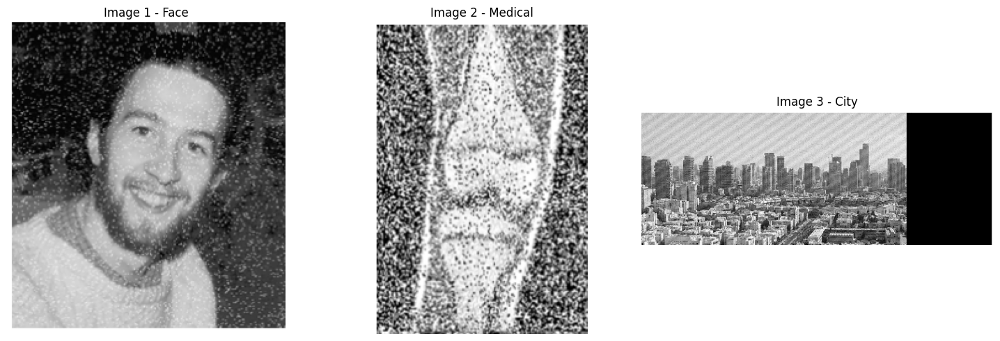

In [5]:
import cv2
import os
import matplotlib.pyplot as plt

# Find all image files
image_files = sorted([
    f for f in os.listdir('/content')
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
])

print("Images found:", image_files)

if len(image_files) < 3:
    raise ValueError("Please upload all 3 images to /content/")

# Load three images
images = {}

names = [
    "Image 1 - Face",
    "Image 2 - Medical",
    "Image 3 - City"
]

for name, filename in zip(names, image_files[:3]):

    path = os.path.join('/content', filename)

    img = cv2.imread(path, 0)

    if img is None:
        raise ValueError(f"Cannot read {filename}")

    images[name] = img

# Display images
plt.figure(figsize=(15, 5))

for i, (name, img) in enumerate(images.items()):
    plt.subplot(1, 3, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(name)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [7]:
noise_types = {
    "Image 1 - Face": "Salt-and-Pepper Noise",
    "Image 2 - Medical": "Impulse Noise",
    "Image 3 - City": "Periodic Stripe Noise"
}

for name, noise in noise_types.items():
    print(f"{name}: {noise}")

Image 1 - Face: Salt-and-Pepper Noise
Image 2 - Medical: Impulse Noise
Image 3 - City: Periodic Stripe Noise


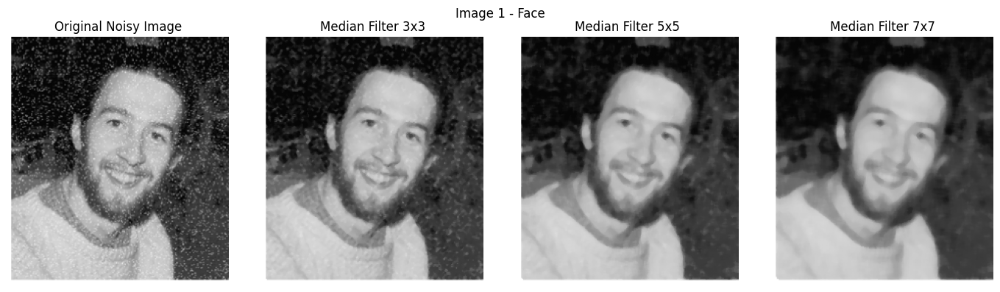

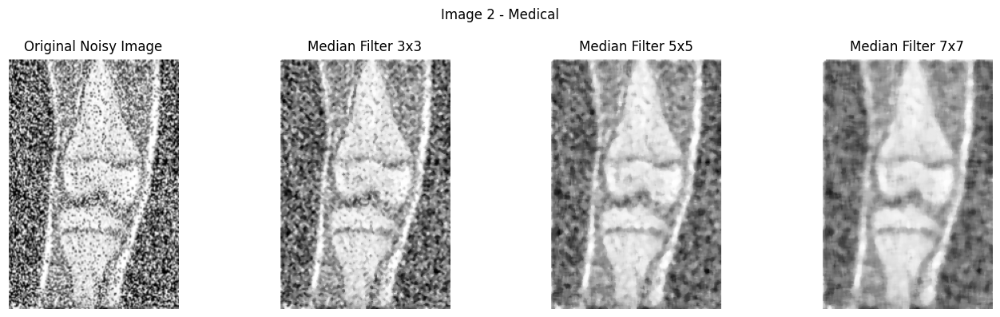

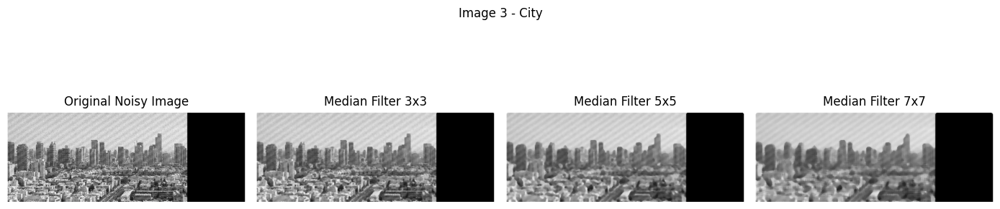

In [8]:
# Apply Median Filtering with different kernel sizes

kernel_sizes = [3, 5, 7]
median_results = {}

for name, img in images.items():

    plt.figure(figsize=(14, 4))

    # Original noisy image
    plt.subplot(1, 4, 1)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.title("Original Noisy Image")
    plt.axis('off')

    # Apply median filters
    for i, k in enumerate(kernel_sizes):

        filtered = cv2.medianBlur(img, k)

        median_results[(name, k)] = filtered

        plt.subplot(1, 4, i + 2)
        plt.imshow(filtered, cmap='gray', vmin=0, vmax=255)
        plt.title(f"Median Filter {k}x{k}")
        plt.axis('off')

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

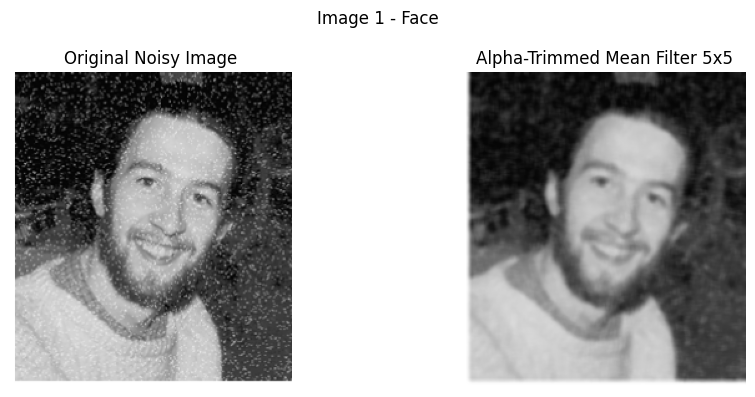

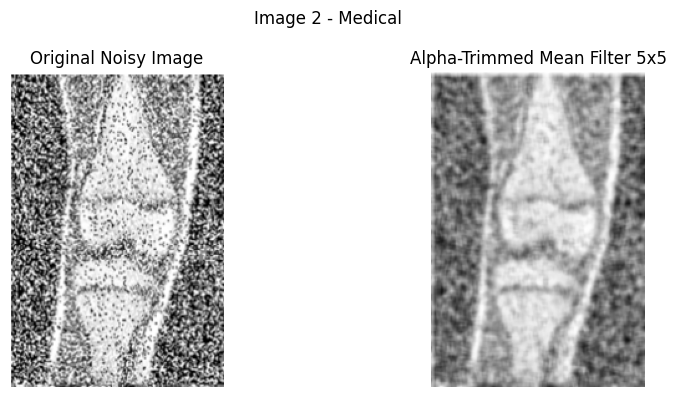

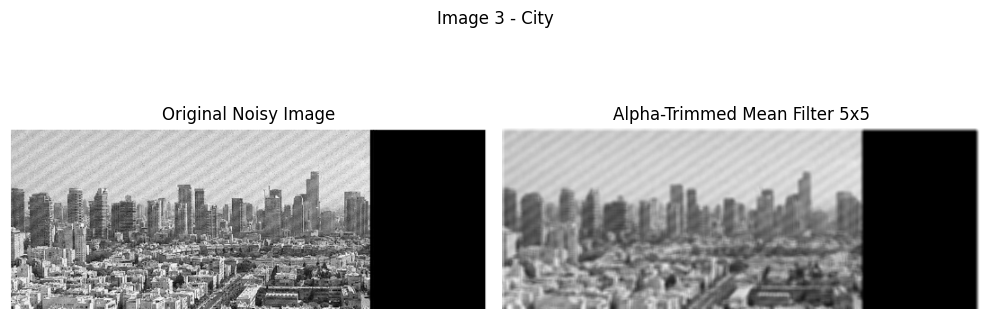

In [9]:
# Alpha-Trimmed Mean Filter

def alpha_trimmed_mean(values, d=4):
    sorted_values = np.sort(values)

    # Remove 2 lowest and 2 highest values
    trimmed = sorted_values[d//2 : len(sorted_values)-d//2]

    return np.mean(trimmed)


alpha_results = {}

for name, img in images.items():

    filtered = generic_filter(
        img.astype(np.float64),
        alpha_trimmed_mean,
        size=5,
        extra_keywords={'d': 4}
    )

    filtered = np.clip(filtered, 0, 255).astype(np.uint8)

    alpha_results[name] = filtered

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.title("Original Noisy Image")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(filtered, cmap='gray', vmin=0, vmax=255)
    plt.title("Alpha-Trimmed Mean Filter 5x5")
    plt.axis('off')

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

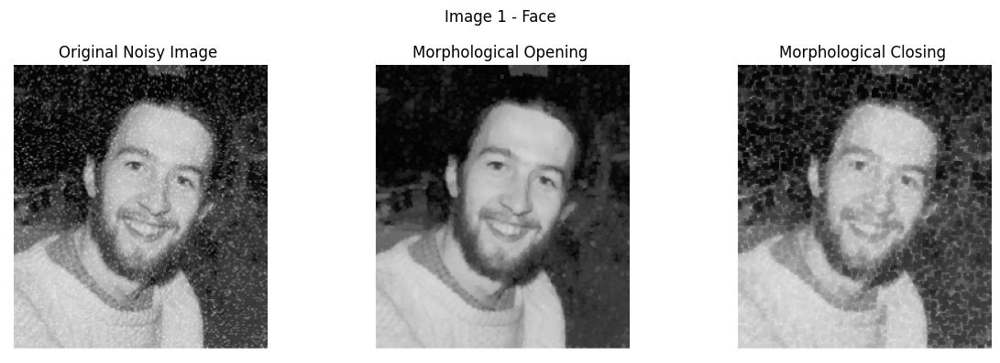

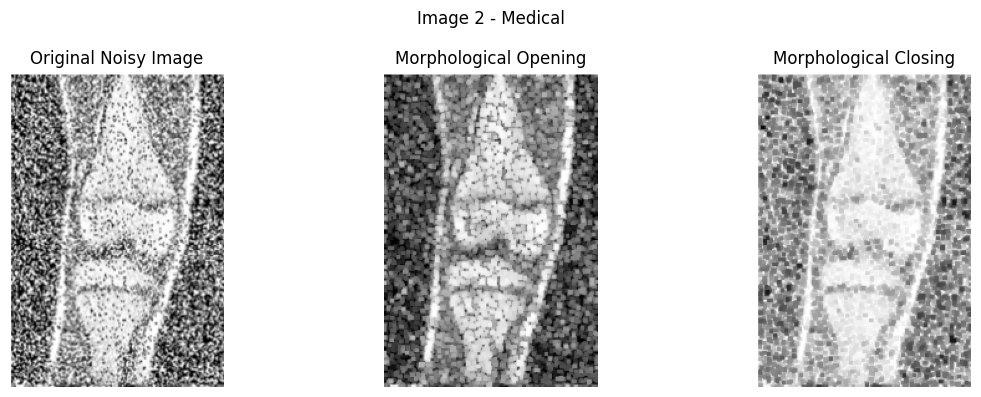

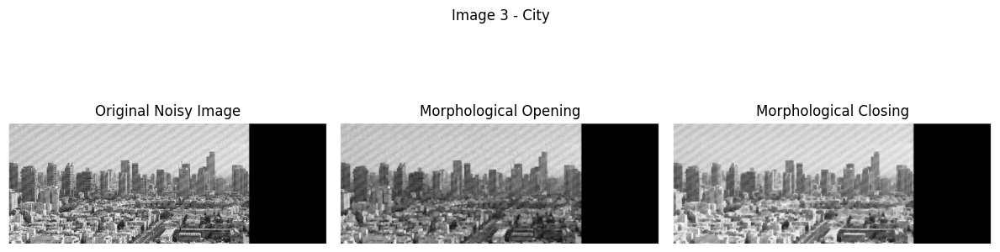

In [10]:
# Morphological Filtering - Opening and Closing

# Create a 3x3 structuring element
kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (3, 3)
)

morph_results = {}

for name, img in images.items():

    # Apply morphological opening
    opening = cv2.morphologyEx(
        img, cv2.MORPH_OPEN, kernel
    )

    # Apply morphological closing
    closing = cv2.morphologyEx(
        img, cv2.MORPH_CLOSE, kernel
    )

    # Store results
    morph_results[(name, "Opening")] = opening
    morph_results[(name, "Closing")] = closing

    # Display results
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.title("Original Noisy Image")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(opening, cmap='gray', vmin=0, vmax=255)
    plt.title("Morphological Opening")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(closing, cmap='gray', vmin=0, vmax=255)
    plt.title("Morphological Closing")
    plt.axis('off')

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

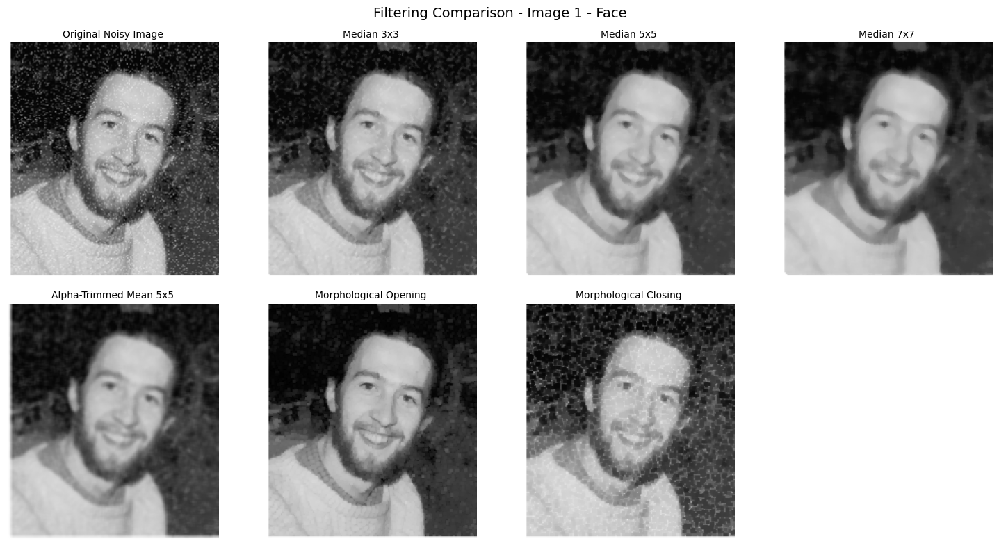

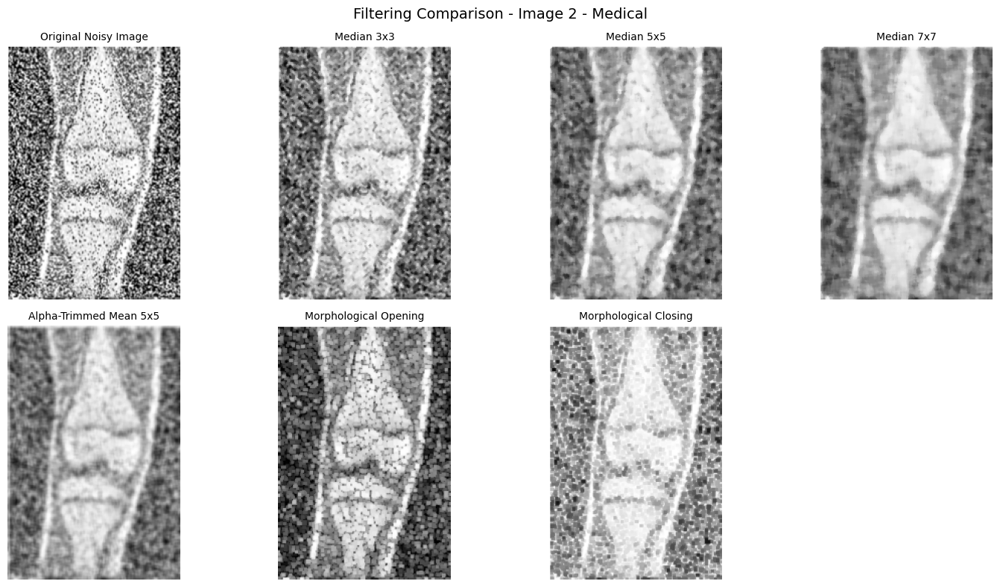

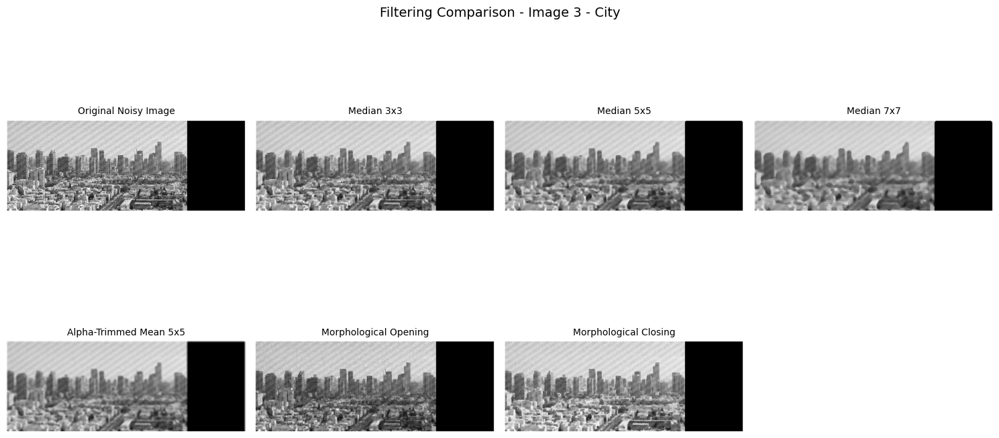

In [11]:
# Compare all non-linear filtering methods

all_results = {}

for name, img in images.items():

    results = {
        "Original Noisy Image": img,
        "Median 3x3": median_results[(name, 3)],
        "Median 5x5": median_results[(name, 5)],
        "Median 7x7": median_results[(name, 7)],
        "Alpha-Trimmed Mean 5x5": alpha_results[name],
        "Morphological Opening": morph_results[(name, "Opening")],
        "Morphological Closing": morph_results[(name, "Closing")]
    }

    all_results[name] = results

    plt.figure(figsize=(15, 8))

    for i, (title, result) in enumerate(results.items()):

        plt.subplot(2, 4, i + 1)

        plt.imshow(
            result,
            cmap='gray',
            vmin=0,
            vmax=255
        )

        plt.title(title, fontsize=10)
        plt.axis('off')

    plt.suptitle(
        f"Filtering Comparison - {name}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

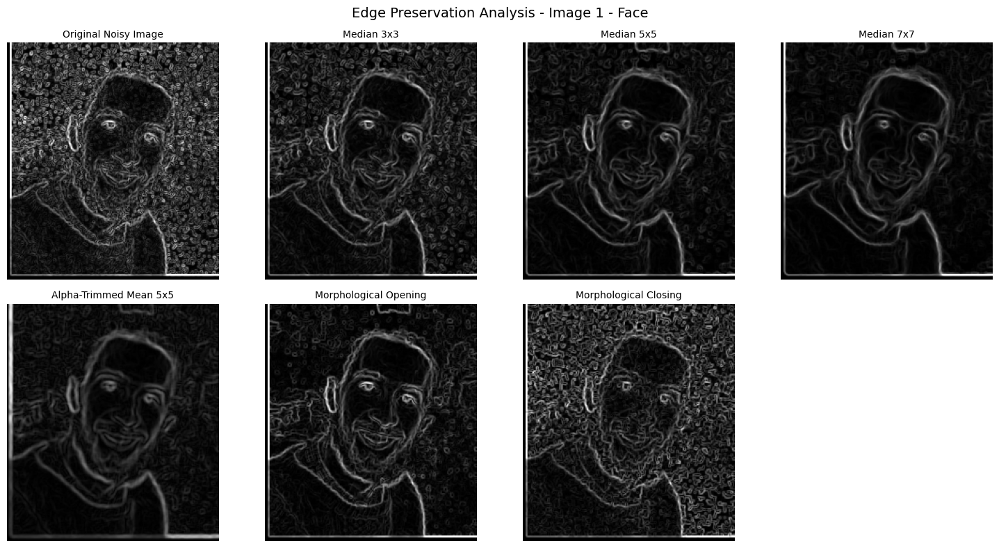

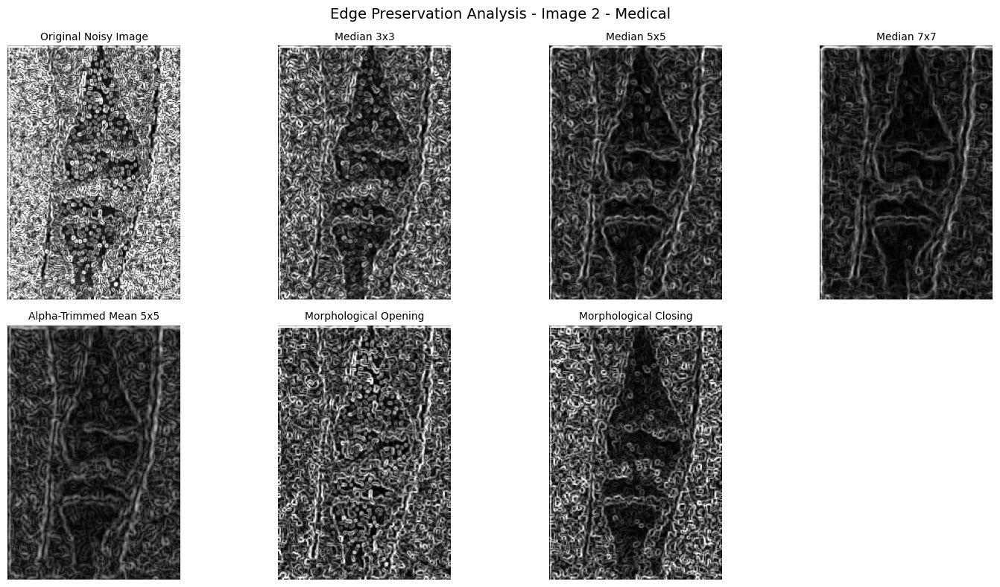

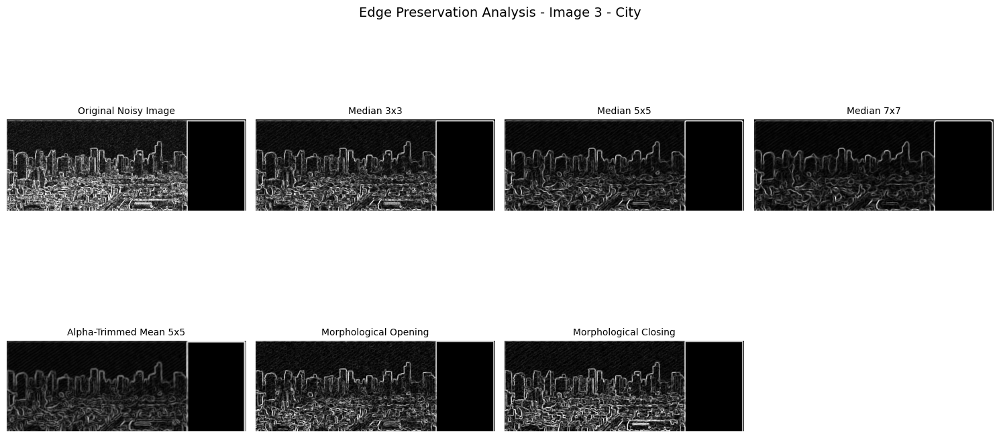

In [12]:
# Edge Preservation Analysis using Sobel Operator

def detect_edges(img):

    # Horizontal edges
    gx = cv2.Sobel(
        img, cv2.CV_64F, 1, 0, ksize=3
    )

    # Vertical edges
    gy = cv2.Sobel(
        img, cv2.CV_64F, 0, 1, ksize=3
    )

    # Calculate edge magnitude
    edges = cv2.magnitude(gx, gy)

    return edges


# Apply edge detection to all filtered images
for name, results in all_results.items():

    plt.figure(figsize=(15, 8))

    for i, (title, img) in enumerate(results.items()):

        edges = detect_edges(img)

        plt.subplot(2, 4, i + 1)

        plt.imshow(
            edges,
            cmap='gray',
            vmin=0,
            vmax=500
        )

        plt.title(title, fontsize=10)
        plt.axis('off')

    plt.suptitle(
        f"Edge Preservation Analysis - {name}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

In [13]:
# Quantitative Analysis of Non-Linear Filters

analysis_results = []

for name, results in all_results.items():

    original = images[name]

    for filter_name, filtered in results.items():

        # 1. Laplacian Variance
        laplacian = cv2.Laplacian(
            filtered, cv2.CV_64F
        )

        lap_variance = laplacian.var()

        # 2. Edge Density
        edges = cv2.Canny(filtered, 100, 200)

        edge_density = np.mean(edges > 0) * 100

        # 3. Mean Absolute Change
        difference = cv2.absdiff(
            original, filtered
        )

        mean_difference = np.mean(difference)

        # Store results
        analysis_results.append({
            "Image": name,
            "Filter": filter_name,
            "Laplacian Variance": lap_variance,
            "Edge Density (%)": edge_density,
            "Mean Absolute Change": mean_difference
        })

# Create DataFrame
df = pd.DataFrame(analysis_results)

print("Quantitative Filter Performance Analysis:")

display(df.round(3))

Quantitative Filter Performance Analysis:


,Image,Filter,Laplacian Variance,Edge Density (%),Mean Absolute Change
0,Image 1 - Face,Original Noisy Image,2099.456,21.825,0.000
1,Image 1 - Face,Median 3x3,576.647,9.677,6.201
2,Image 1 - Face,Median 5x5,321.971,4.259,9.227
3,Image 1 - Face,Median 7x7,256.196,2.931,10.417
4,Image 1 - Face,Alpha-Trimmed Mean 5x5,36.238,1.966,10.634
5,Image 1 - Face,Morphological Opening,532.454,6.064,7.662
6,Image 1 - Face,Morphological Closing,1210.948,17.531,6.657
7,Image 2 - Medical,Original Noisy Image,10340.176,37.007,0.000
8,Image 2 - Medical,Median 3x3,3019.500,31.818,17.898
9,Image 2 - Medical,Median 5x5,963.423,21.266,29.822


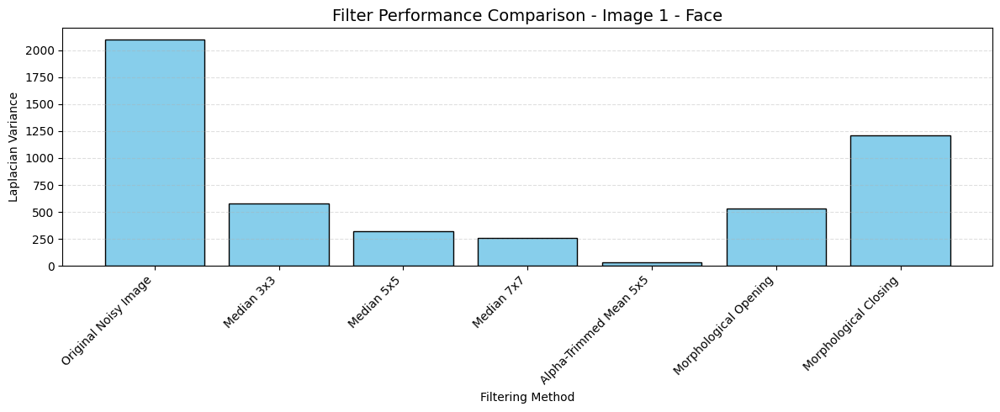

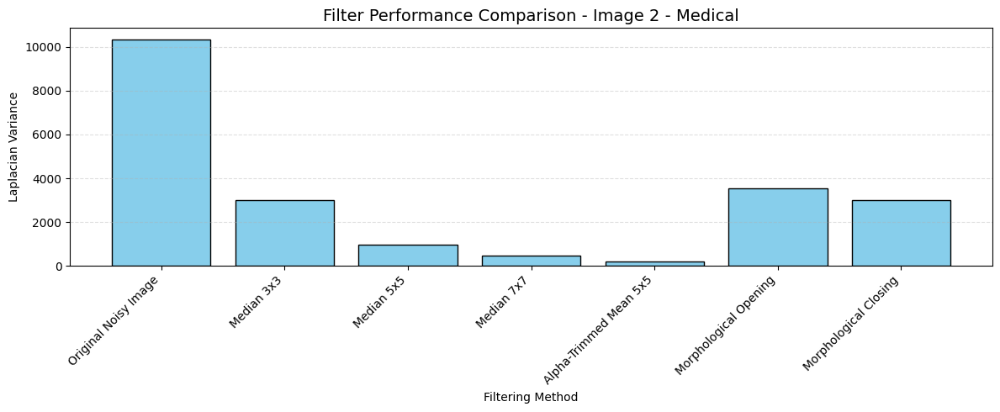

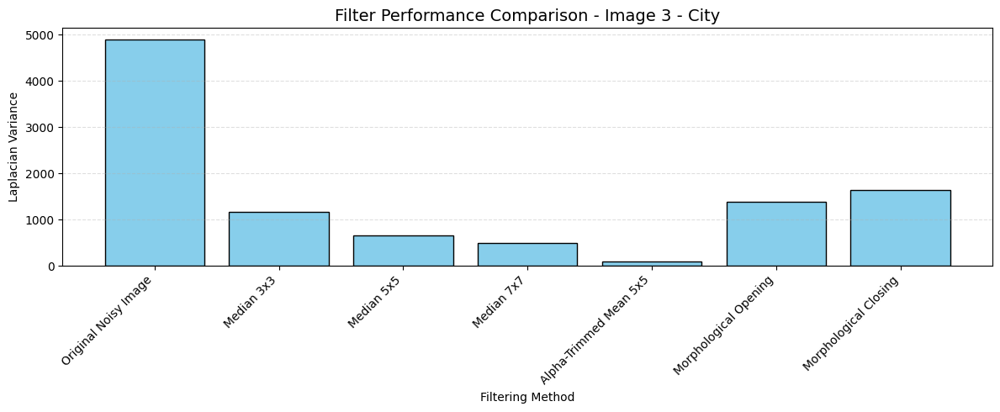

In [14]:
# Graphical Comparison of Non-Linear Filters

for name in images.keys():

    # Select results for the current image
    subset = df[df["Image"] == name]

    plt.figure(figsize=(12, 5))

    # Plot Laplacian Variance
    plt.bar(
        subset["Filter"],
        subset["Laplacian Variance"],
        color="skyblue",
        edgecolor="black"
    )

    plt.title(
        f"Filter Performance Comparison - {name}",
        fontsize=14
    )

    plt.xlabel("Filtering Method")
    plt.ylabel("Laplacian Variance")

    plt.xticks(rotation=45, ha="right")

    plt.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()

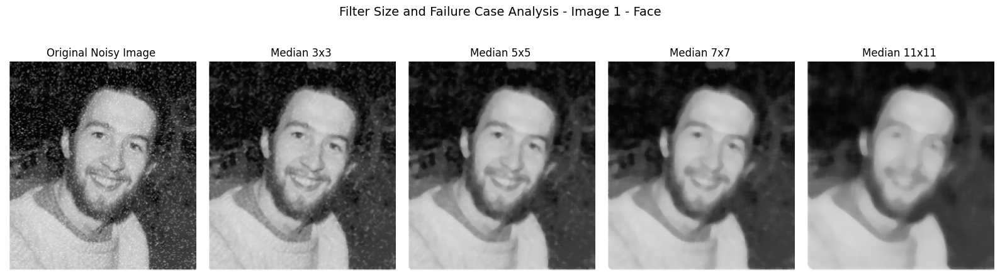

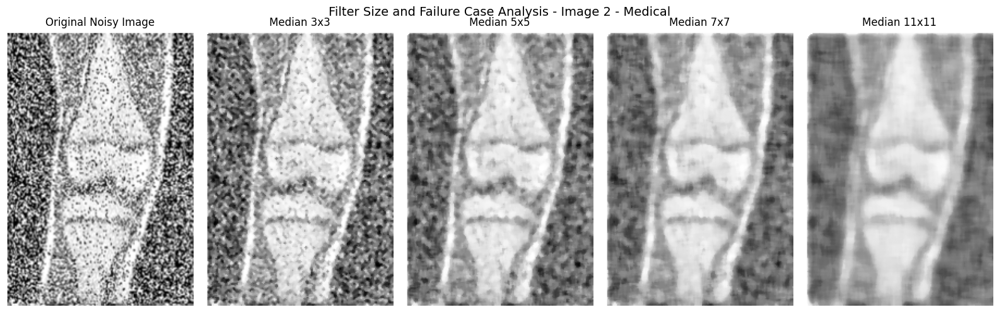

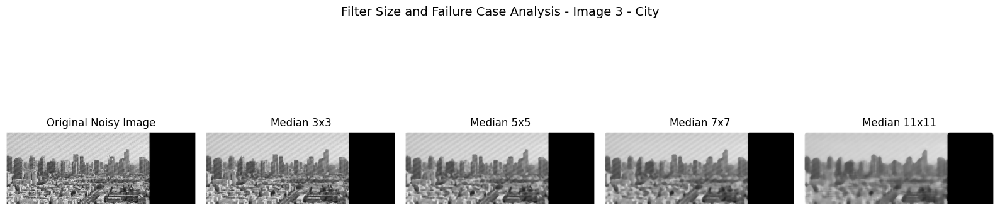

In [15]:
# Filter Size Analysis and Failure Cases

filter_sizes = [3, 5, 7, 11]

for name, img in images.items():

    plt.figure(figsize=(16, 5))

    # Original noisy image
    plt.subplot(1, 5, 1)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.title("Original Noisy Image")
    plt.axis('off')

    # Apply median filters of different sizes
    for i, k in enumerate(filter_sizes):

        filtered = cv2.medianBlur(img, k)

        plt.subplot(1, 5, i + 2)
        plt.imshow(
            filtered,
            cmap='gray',
            vmin=0,
            vmax=255
        )

        plt.title(f"Median {k}x{k}")
        plt.axis('off')

    plt.suptitle(
        f"Filter Size and Failure Case Analysis - {name}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

In [16]:
# Compare Median Filter Window Sizes

optimum_analysis = []

for name, img in images.items():

    for k in [3, 5, 7, 11]:

        filtered = cv2.medianBlur(img, k)

        # Measure high-frequency activity
        lap_var = cv2.Laplacian(
            filtered, cv2.CV_64F
        ).var()

        # Measure edge density
        edges = cv2.Canny(filtered, 100, 200)
        edge_density = np.mean(edges > 0) * 100

        # Measure average pixel change
        mean_change = np.mean(
            cv2.absdiff(img, filtered)
        )

        optimum_analysis.append({
            "Image": name,
            "Window Size": f"{k}x{k}",
            "Laplacian Variance": lap_var,
            "Edge Density (%)": edge_density,
            "Mean Absolute Change": mean_change
        })

optimum_df = pd.DataFrame(optimum_analysis)

print("Median Filter Size Comparison:")
display(optimum_df.round(3))

Median Filter Size Comparison:


,Image,Window Size,Laplacian Variance,Edge Density (%),Mean Absolute Change
0,Image 1 - Face,3x3,576.647,9.677,6.201
1,Image 1 - Face,5x5,321.971,4.259,9.227
2,Image 1 - Face,7x7,256.196,2.931,10.417
3,Image 1 - Face,11x11,198.162,2.258,11.833
4,Image 2 - Medical,3x3,3019.500,31.818,17.898
5,Image 2 - Medical,5x5,963.423,21.266,29.822
6,Image 2 - Medical,7x7,477.102,11.451,33.953
7,Image 2 - Medical,11x11,194.120,3.017,37.239
8,Image 3 - City,3x3,1170.240,11.456,8.731
9,Image 3 - City,5x5,658.349,7.963,11.490



Image: Image 1 - Face


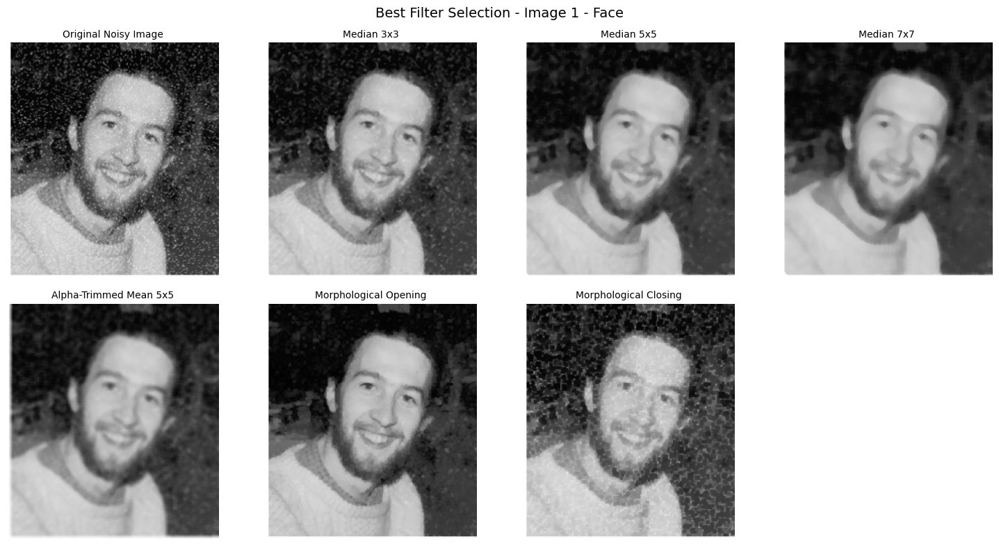


Image: Image 2 - Medical


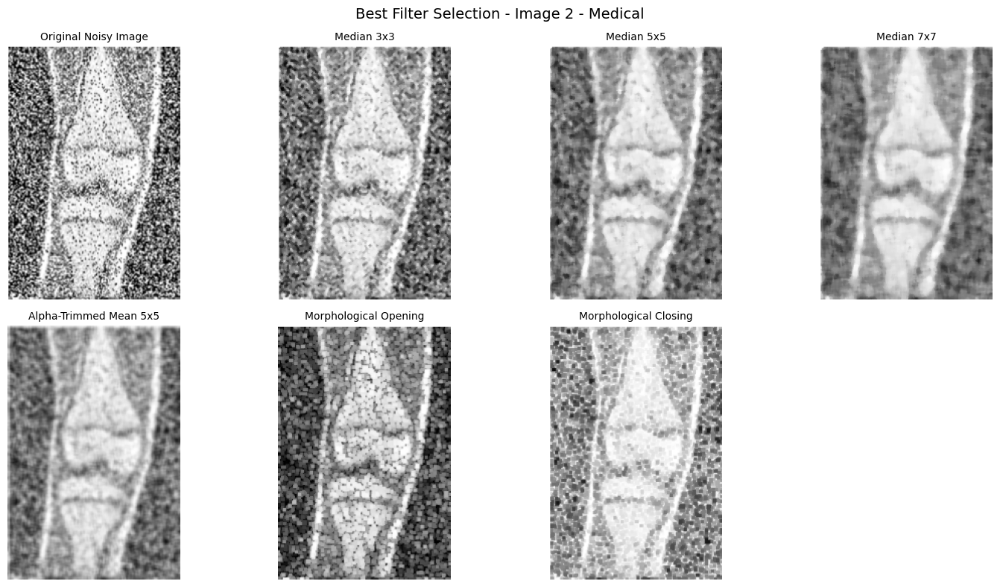


Image: Image 3 - City


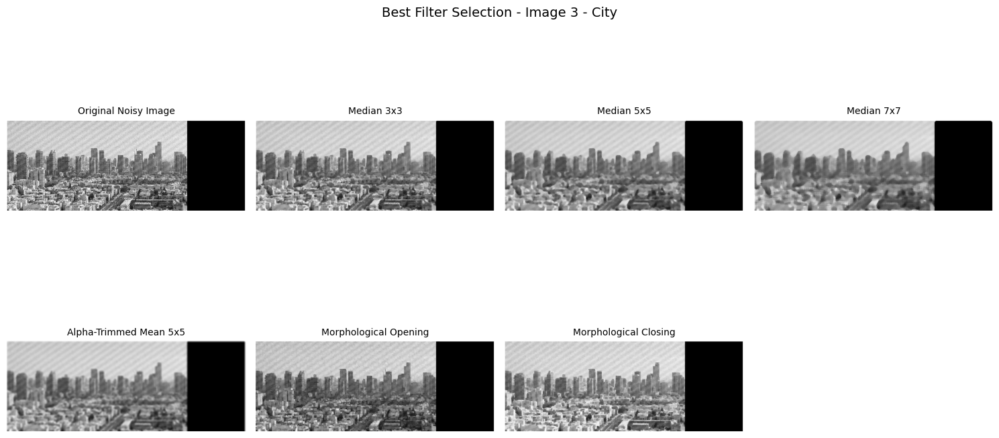

In [17]:
# Best Performing Filter Comparison

for name, results in all_results.items():

    print("\nImage:", name)

    plt.figure(figsize=(15, 8))

    for i, (filter_name, filtered) in enumerate(results.items()):

        plt.subplot(2, 4, i + 1)
        plt.imshow(filtered, cmap='gray', vmin=0, vmax=255)
        plt.title(filter_name, fontsize=10)
        plt.axis('off')

    plt.suptitle(
        f"Best Filter Selection - {name}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()